# Level 2 – Task 3: Clustering Analysis (K-Means)
**Dataset:** Iris Dataset (cleaned)  
**Tools:** Python, scikit-learn, matplotlib, seaborn

## 1. Load the Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import os

os.makedirs('plots', exist_ok=True)

df = pd.read_csv('../Level1/iris_cleaned.csv')
print('Shape:', df.shape)
df.head()

Shape: (148, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Standardize the Dataset

In [2]:
num_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[num_cols])

print('Mean after scaling:', X_scaled.mean(axis=0).round(4))
print('Std after scaling :', X_scaled.std(axis=0).round(4))

Mean after scaling: [ 0. -0.  0. -0.]
Std after scaling : [1. 1. 1. 1.]


## 3. Elbow Method – Optimal Number of Clusters

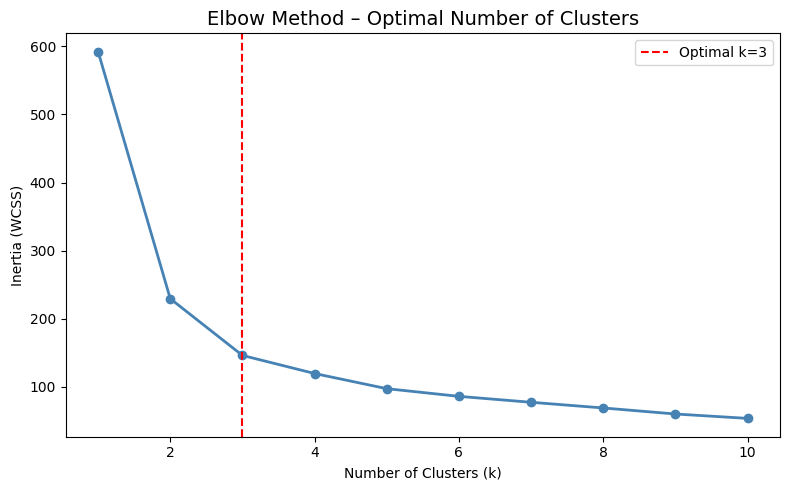

In [3]:
inertia = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', color='steelblue', linewidth=2)
plt.axvline(x=3, color='red', linestyle='--', label='Optimal k=3')
plt.title('Elbow Method – Optimal Number of Clusters', fontsize=14)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.legend()
plt.tight_layout()
plt.savefig('plots/kmeans_elbow.png', dpi=150)
plt.show()

## 4. Apply K-Means with k=3

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print('Cluster distribution:')
print(df['cluster'].value_counts().sort_index())

Cluster distribution:
cluster
0    45
1    48
2    55
Name: count, dtype: int64


## 5. Visualize Clusters – Petal Features

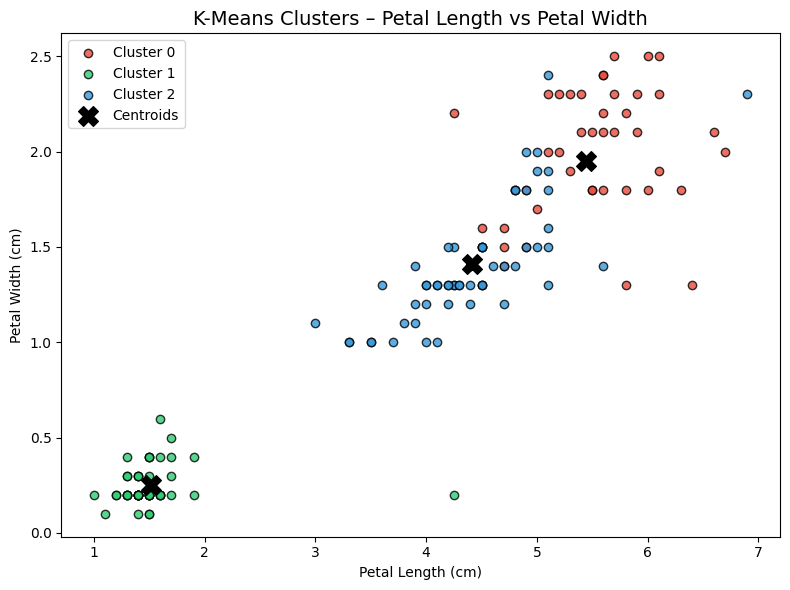

In [5]:
palette = {0: '#e74c3c', 1: '#2ecc71', 2: '#3498db'}

plt.figure(figsize=(8, 6))
for cluster, group in df.groupby('cluster'):
    plt.scatter(group['petal_length'], group['petal_width'],
                label=f'Cluster {cluster}', color=palette[cluster],
                edgecolors='black', alpha=0.8)

# Plot centroids (inverse transform to original scale)
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 2], centers[:, 3], marker='X', s=200,
            color='black', zorder=5, label='Centroids')

plt.title('K-Means Clusters – Petal Length vs Petal Width', fontsize=14)
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend()
plt.tight_layout()
plt.savefig('plots/kmeans_petal_clusters.png', dpi=150)
plt.show()

## 6. Visualize Clusters – Sepal Features

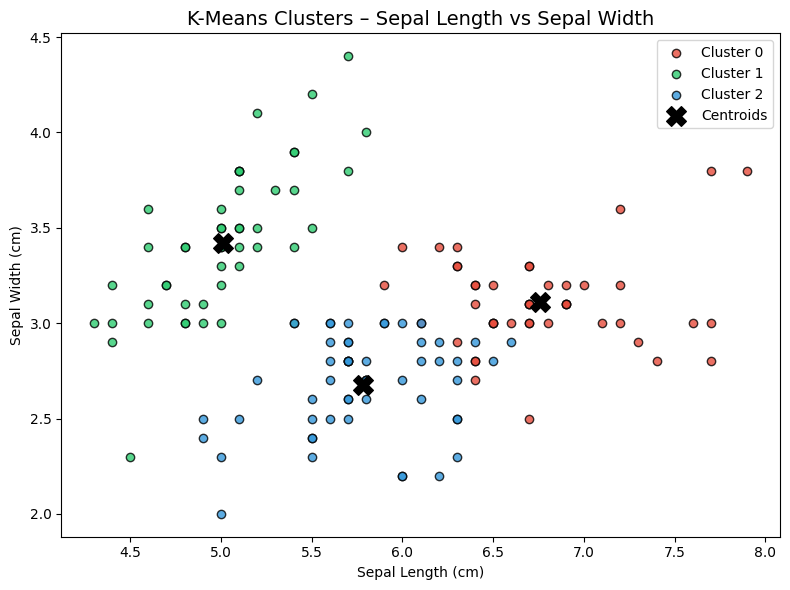

In [6]:
plt.figure(figsize=(8, 6))
for cluster, group in df.groupby('cluster'):
    plt.scatter(group['sepal_length'], group['sepal_width'],
                label=f'Cluster {cluster}', color=palette[cluster],
                edgecolors='black', alpha=0.8)

plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=200,
            color='black', zorder=5, label='Centroids')

plt.title('K-Means Clusters – Sepal Length vs Sepal Width', fontsize=14)
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.legend()
plt.tight_layout()
plt.savefig('plots/kmeans_sepal_clusters.png', dpi=150)
plt.show()

## 7. Compare Clusters vs Actual Species

In [7]:
print('Cluster vs Actual Species:')
print(pd.crosstab(df['cluster'], df['species']))

Cluster vs Actual Species:
species  setosa  versicolor  virginica
cluster                               
0             0          10         35
1            46           1          1
2             0          40         15


## Summary

| Step | Result |
|------|--------|
| Standardization | All features scaled to mean=0, std=1 |
| Elbow Method | Optimal k=3 (matches the 3 iris species) |
| Clustering | K-Means correctly separates Setosa; slight overlap between Versicolor and Virginica |
| Centroids | Marked with X on scatter plots |